In [2]:
import os
from configparser import ConfigParser
from matplotlib import pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import seaborn as sns

In [3]:
os.getcwd()

'/Users/janik/source/urban-mobility-simulation/resources/scripts/simulation_analysis'

In [4]:
os.chdir("../../../")
os.getcwd()

'/Users/janik/source/urban-mobility-simulation'

In [5]:
from simulation.helper.time import SimulationTimeConverter

In [6]:
# Read args
parser = ConfigParser()
parser.read("resources/configurations/shared-charging.ini")

['resources/configurations/shared-charging.ini']

In [7]:
auction_tracking = pd.read_csv("data/output/tracking/auction.csv")

In [34]:
auction_tracking

,time,timeslot,location,results.capacity,results.clearing_price,bids
0,0,30,872664c1effffff,0.0,0.000000,NaN
1,0,30,872664c1affffff,0.0,0.000000,NaN
2,0,30,87275934effffff,0.0,0.000000,NaN
3,0,30,872664cadffffff,0.0,0.000000,NaN
4,0,30,872664c16ffffff,0.0,0.000000,NaN
...,...,...,...,...,...,...
2227,1365,1395,872664cf5ffffff,0.0,0.000000,NaN
2228,1365,1395,872664cacffffff,0.0,0.000000,NaN
2229,1365,1395,872664c10ffffff,0.0,0.000000,NaN
2230,1365,1395,872664d89ffffff,0.0,0.000000,NaN


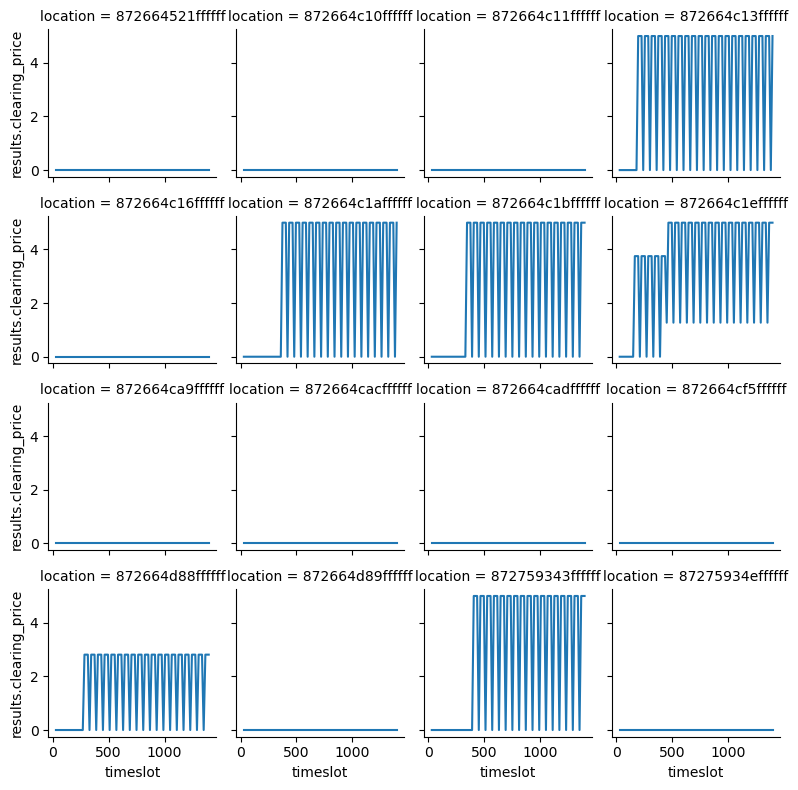

In [35]:
auction_tracking.sort_values(by=['time', 'location'], inplace=True)
sns.relplot(data=auction_tracking, x="timeslot", y="results.clearing_price", col="location", col_wrap=4, kind="line", height=2)

In [8]:
vehicle_tracking = pd.read_csv("data/output/tracking/vehicles.csv")

In [10]:
RECHARGE_THRESHOLD = 40 # ATTENTION: This is an approximation, we use dynamic ones per base region

vehicle_tracking['fleet_average_SOC'] = vehicle_tracking['_current_state_of_charge'].apply(lambda x: np.mean(eval(x)))
vehicle_tracking['fleet_number_low_SOC'] = vehicle_tracking['_current_state_of_charge'].apply(lambda x: np.count_nonzero(np.array(eval(x))< RECHARGE_THRESHOLD))

In [11]:
# rename time axis
vehicle_tracking['time'] = pd.to_datetime(vehicle_tracking['time'].apply(SimulationTimeConverter.as_time), format="%H:%M:%S")

vehicle_tracking['timestamp'] = vehicle_tracking['time'].dt.strftime("%H:%M")

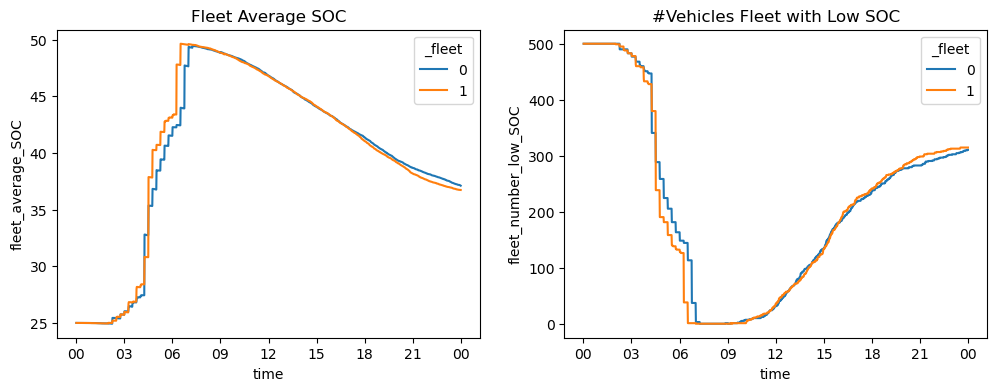

In [12]:
fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize = (12, 4))

sns.lineplot(data=vehicle_tracking, x='time', y='fleet_average_SOC', hue='_fleet', ax = ax[0])
sns.lineplot(data=vehicle_tracking, x='time', y='fleet_number_low_SOC', hue='_fleet', ax = ax[1])

ax[0].set_title('Fleet Average SOC')
ax[1].set_title('#Vehicles Fleet with Low SOC')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

In [13]:
INITIALIZED = 0
PARKING = 1
DRIVING = 2
RELOCATING = 3
CHARGING = 4
PRE_SERVICE = 5
ONLINE = 6  # When the driver is online
OFFLINE = 7  # When the driver is offline
SOME_STATE = 1002
RESERVED = 1001
MOVING_TO_PICK_UP_POS = 1003

In [14]:
vehicle_tracking['_state_PARKING'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == PARKING))

vehicle_tracking['_state_CHARGING'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == CHARGING))

vehicle_tracking['_state_DRIVING'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == DRIVING))

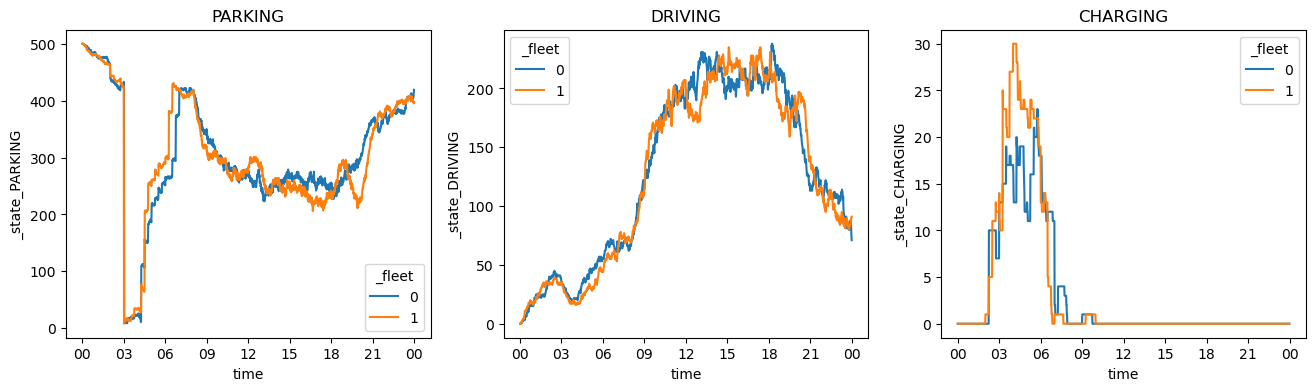

In [15]:
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))
sns.lineplot(data=vehicle_tracking, x='time', y='_state_PARKING', hue='_fleet', ax=ax[0])
sns.lineplot(data=vehicle_tracking, x='time', y='_state_DRIVING', hue='_fleet', ax=ax[1])
sns.lineplot(data=vehicle_tracking, x='time', y='_state_CHARGING', hue='_fleet', ax=ax[2])

ax[0].set_title('PARKING')
ax[1].set_title('DRIVING')
ax[2].set_title('CHARGING')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

In [16]:
charging_station_tracking = pd.read_csv("data/output/tracking/charging_stations.csv")

In [17]:
CHARGING_STATION_CAPACITY = parser.getint("CHARGING_INFRASTRUCTURE", "CHARGING_STATION_CAPACITY")

In [18]:
charging_station_tracking['utilization'] = charging_station_tracking['_plugs.count'] / CHARGING_STATION_CAPACITY

charging_station_tracking['system_wide_utilization'] = charging_station_tracking.groupby('time')['utilization'].transform('mean')

In [19]:
# rename time axis
charging_station_tracking['time'] = pd.to_datetime(charging_station_tracking['time'].apply(SimulationTimeConverter.as_time), format="%H:%M:%S")

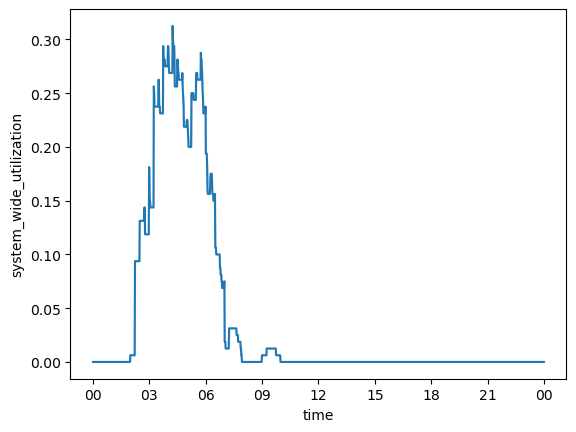

In [20]:
g = sns.lineplot(data=charging_station_tracking, x='time', y='system_wide_utilization')

ax = g.axes

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

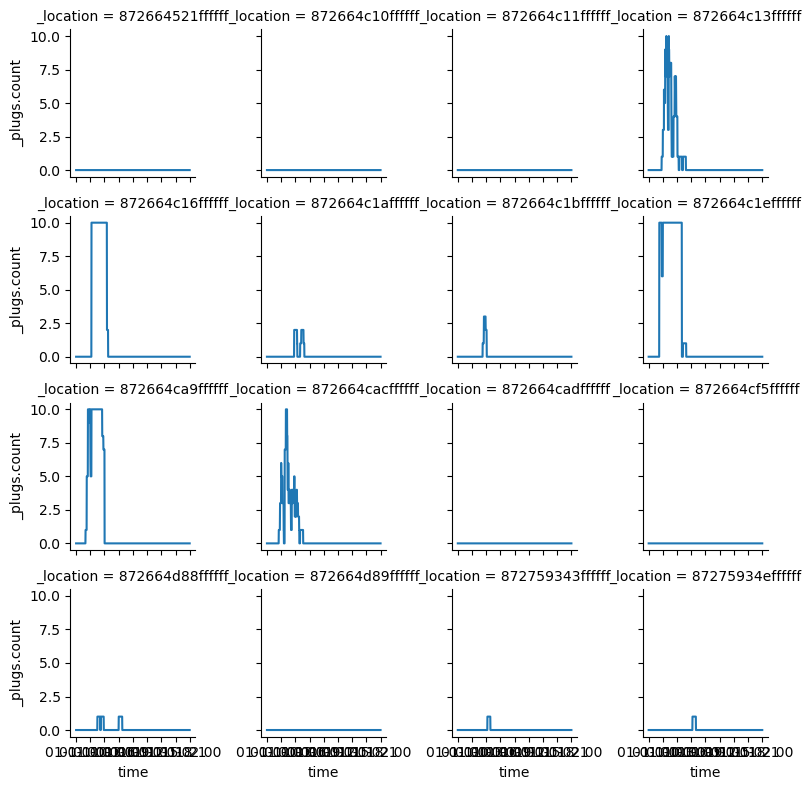

In [21]:
charging_station_tracking.sort_values(by=['time', '_location'], inplace=True)
sns.relplot(
    data=charging_station_tracking, x='time', y='_plugs.count', col='_location', kind='line', col_wrap=4, height=2)

## Transactions

In [65]:
transactions_fleet_0 = pd.read_csv("data/output/transactions/fleet_0_transactions.csv")
transactions_fleet_1 = pd.read_csv("data/output/transactions/fleet_1_transactions.csv")

In [66]:
RESAMPLE_RATE = '1h'

In [67]:
transactions_fleet_0['timestamp'] = transactions_fleet_0['time_end'].apply(SimulationTimeConverter.as_time)
transactions_fleet_0['timestamp'] = pd.to_datetime(transactions_fleet_0['timestamp'], format="%H:%M:%S")
transactions_fleet_0_resampled = transactions_fleet_0.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

transactions_fleet_1['timestamp'] = transactions_fleet_1['time_end'].apply(SimulationTimeConverter.as_time)
transactions_fleet_1['timestamp'] = pd.to_datetime(transactions_fleet_1['timestamp'], format="%H:%M:%S")
transactions_fleet_1_resampled = transactions_fleet_1.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

In [68]:
# normalize
transactions_fleet_0_resampled = transactions_fleet_0_resampled.div(transactions_fleet_0_resampled.sum(axis=1), axis=0)

transactions_fleet_1_resampled = transactions_fleet_1_resampled.div(transactions_fleet_1_resampled.sum(axis=1), axis=0)

# rename time axis
transactions_fleet_0_resampled['timestamp'] = transactions_fleet_0_resampled.index.strftime("%H:%M")

transactions_fleet_1_resampled['timestamp'] = transactions_fleet_1_resampled.index.strftime("%H:%M")

Text(0.5, 1.0, 'Fleet 1')

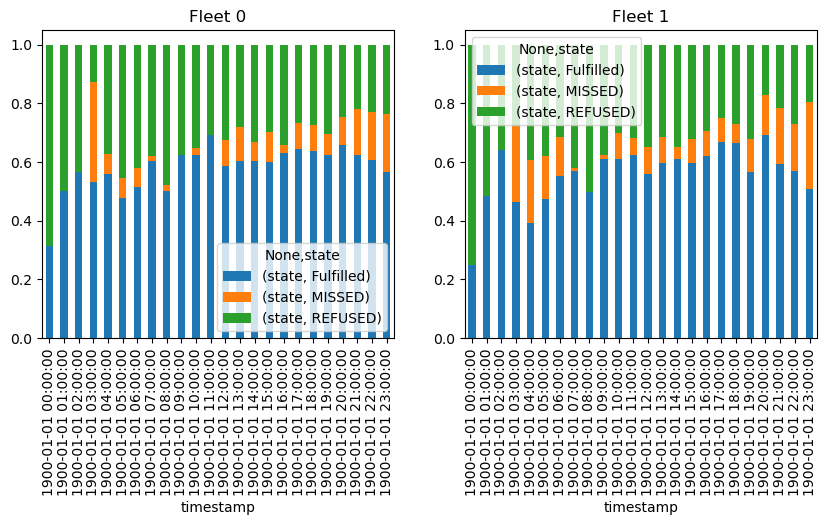

In [69]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

transactions_fleet_0_resampled.plot(kind = 'bar', stacked=True, ax=ax[0])
transactions_fleet_1_resampled.plot(kind = 'bar', stacked=True, ax=ax[1])

ax[0].set_title('Fleet 0')
ax[1].set_title('Fleet 1')

(0.0, 1.0)

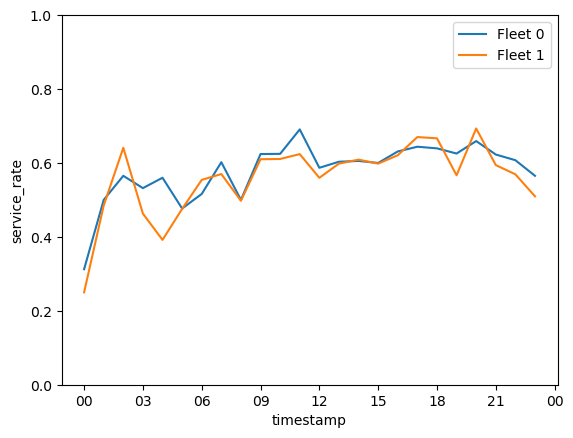

In [70]:
transactions_fleet_0_resampled['service_rate'] = transactions_fleet_0_resampled[('state', 'Fulfilled')]
transactions_fleet_1_resampled['service_rate'] = transactions_fleet_1_resampled[('state', 'Fulfilled')]

# service_rate_mean = transactions_fleet_0_resampled.reset_index()[['timestamp', 'service_rate']].join(transactions_fleet_1_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')

sns.lineplot(data=transactions_fleet_0_resampled, x = transactions_fleet_0_resampled.index, y = 'service_rate', label='Fleet 0')
sns.lineplot(data=transactions_fleet_1_resampled, x = transactions_fleet_1_resampled.index, y = 'service_rate', label='Fleet 1')

ax = plt.gca()

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

ax.set_ylim(0, 1.0)

### Vehilce Distance Travelled: Service vs. Operations

In [96]:
vehicle_tracking['fleet_vdt'] = vehicle_tracking['_vdt'].apply(lambda x: sum(eval(x)))

In [97]:
service_vdt_fleet_0 = transactions_fleet_0[transactions_fleet_0['state'] == 'Fulfilled'].resample(RESAMPLE_RATE, on = 'timestamp').agg({'distance': 'sum'})
service_vdt_fleet_1 = transactions_fleet_1[transactions_fleet_1['state'] == 'Fulfilled'].resample(RESAMPLE_RATE, on = 'timestamp').agg({'distance': 'sum'})

In [98]:
service_vdt_fleet_0['cumsum'] = service_vdt_fleet_0.cumsum()
service_vdt_fleet_1['cumsum'] = service_vdt_fleet_1.cumsum()

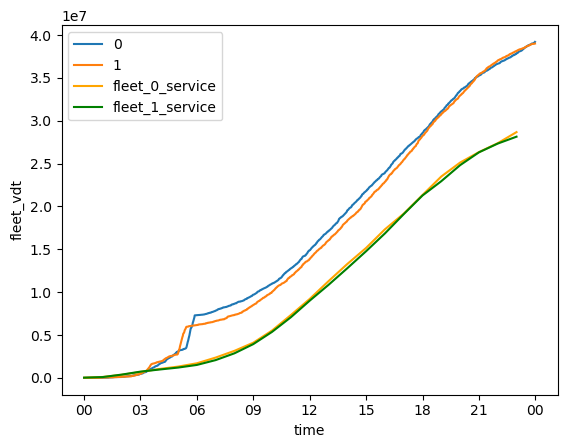

In [99]:
sns.lineplot(data=vehicle_tracking, x='time', y='fleet_vdt', hue='_fleet')
sns.lineplot(data=service_vdt_fleet_0, x='timestamp', y='cumsum', color='orange', label='fleet_0_service')
sns.lineplot(data=service_vdt_fleet_1, x='timestamp', y='cumsum', color='green', label='fleet_1_service')

ax = plt.gca()

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

In [107]:
# share of operations VDT (excl customer serving)
hourly_vdt = vehicle_tracking.groupby('_fleet').resample(RESAMPLE_RATE, on = 'time').agg({'fleet_vdt': 'max'}).unstack(level=0).rename(columns={0: 'fleet_0_vdt_cumsum', 1: 'fleet_1_vdt_cumsum'}).droplevel(0, axis=1)

In [108]:
hourly_vdt = hourly_vdt.join(service_vdt_fleet_0)

hourly_vdt = hourly_vdt.join(service_vdt_fleet_1, rsuffix='_service_fleet_1')

hourly_vdt.rename(columns={'distance': 'distance_service_fleet_0', 'cumsum': 'cumsum_service_fleet_0'}, inplace=True)

hourly_vdt['fleet_0_ratio_of_empty_vdt'] = (hourly_vdt['fleet_0_vdt_cumsum'] - hourly_vdt['cumsum_service_fleet_0']) / hourly_vdt['fleet_0_vdt_cumsum']

hourly_vdt['fleet_1_ratio_of_empty_vdt'] = (hourly_vdt['fleet_1_vdt_cumsum'] - hourly_vdt['cumsum_service_fleet_1']) / hourly_vdt['fleet_1_vdt_cumsum']

In [111]:
hourly_vdt['fleet_0_vdt'] = hourly_vdt['fleet_0_vdt_cumsum'].diff().fillna(hourly_vdt['fleet_0_vdt_cumsum'].iloc[0])

hourly_vdt['fleet_1_vdt'] = hourly_vdt['fleet_1_vdt_cumsum'].diff().fillna(hourly_vdt['fleet_1_vdt_cumsum'].iloc[0])


In [114]:
hourly_vdt['fleet_0_ratio_of_empty_vdt'] = (hourly_vdt['fleet_0_vdt'] - hourly_vdt['distance_service_fleet_0']) / hourly_vdt['fleet_0_vdt']

hourly_vdt['fleet_1_ratio_of_empty_vdt'] = (hourly_vdt['fleet_1_vdt'] - hourly_vdt['distance_service_fleet_1']) / hourly_vdt['fleet_1_vdt']

In [115]:
hourly_vdt

,fleet_0_vdt_cumsum,fleet_1_vdt_cumsum,distance_service_fleet_0,cumsum_service_fleet_0,distance_service_fleet_1,cumsum_service_fleet_1,fleet_0_ratio_of_empty_vdt,fleet_1_ratio_of_empty_vdt,fleet_0_vdt,fleet_1_vdt
time,,,,,,,,,,
1900-01-01 00:00:00,2.276091e+04,3.528958e+04,1.877614e+04,1.877614e+04,2.933916e+04,2.933916e+04,0.175071,0.168617,2.276091e+04,3.528958e+04
1900-01-01 01:00:00,1.078486e+05,1.188919e+05,9.430334e+04,1.130795e+05,7.198624e+04,1.013254e+05,-0.108308,0.138944,8.508767e+04,8.360227e+04
1900-01-01 02:00:00,4.614878e+05,4.623063e+05,2.457593e+05,3.588388e+05,2.861873e+05,3.875127e+05,0.305056,0.166642,3.536392e+05,3.434144e+05
1900-01-01 03:00:00,1.573322e+06,1.883596e+06,3.369308e+05,6.957696e+05,3.463276e+05,7.338403e+05,0.696959,0.756329,1.111834e+06,1.421290e+06
1900-01-01 04:00:00,3.073569e+06,2.790988e+06,3.473417e+05,1.043111e+06,2.441490e+05,9.779893e+05,0.768477,0.730933,1.500247e+06,9.073917e+05
1900-01-01 05:00:00,7.324405e+06,6.166334e+06,2.777862e+05,1.320898e+06,2.291648e+05,1.207154e+06,0.934651,0.932106,4.250836e+06,3.375346e+06
1900-01-01 06:00:00,7.834872e+06,6.633866e+06,3.868929e+05,1.707790e+06,3.090662e+05,1.516220e+06,0.242081,0.338942,5.104672e+05,4.675326e+05
1900-01-01 07:00:00,8.637573e+06,7.326700e+06,6.670316e+05,2.374822e+06,5.641540e+05,2.080374e+06,0.169016,0.185730,8.027008e+05,6.928339e+05
1900-01-01 08:00:00,9.696317e+06,8.488926e+06,7.872465e+05,3.162068e+06,7.935626e+05,2.873937e+06,0.256434,0.317205,1.058744e+06,1.162226e+06


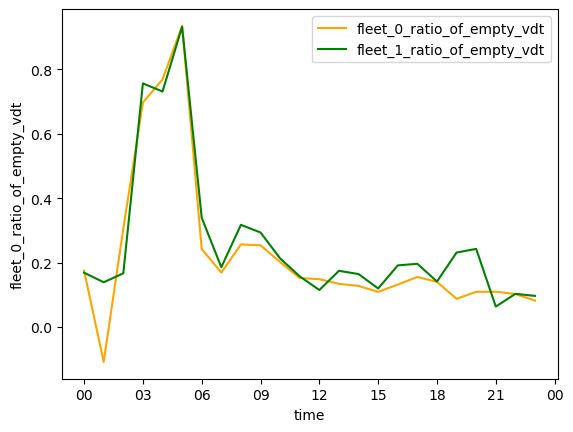

In [116]:
sns.lineplot(data=hourly_vdt, x='time', y='fleet_0_ratio_of_empty_vdt', color='orange', label='fleet_0_ratio_of_empty_vdt')
sns.lineplot(data=hourly_vdt, x='time', y='fleet_1_ratio_of_empty_vdt', color='green', label='fleet_1_ratio_of_empty_vdt')

ax = plt.gca()

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H'))